![Python Banner](../../Image/05_03_uplift_learners.png)


# 3.2 Uplift Tree-Regression


## Overview

Uplift modeling with **continuous outcomes** — often called *uplift regression* or *heterogeneous treatment effect regression* — estimates how the causal effect of a treatment varies across individuals when the outcome of interest is a real-valued metric rather than a binary event. Examples include exam scores, revenue per customer, time spent on a platform, blood pressure reduction, or any other quantity that varies continuously across individuals and could plausibly be affected by an intervention.

The estimand is the **Conditional Average Treatment Effect**:

$$\tau(x) = \mathbb{E}[Y \mid T=1, X=x] - \mathbb{E}[Y \mid T=0, X=x]$$

where $T=1$ denotes treatment, $T=0$ control, $Y \in \mathbb{R}$ the continuous outcome, and $x$ the individual's covariate vector. As in the binary case, the goal is to estimate $\tau(x)$ accurately across the covariate space — but now the effect is a real-valued quantity rather than a probability difference, and the splitting criteria, leaf estimators, and evaluation metrics must be adapted accordingly.

---

### From Classification to Regression

In the binary uplift setting, the tree maximizes divergence between the treated and control **outcome distributions** within each leaf — a natural criterion when outcomes are categorical. With continuous outcomes, distributional divergence is replaced by criteria that directly measure **treatment effect heterogeneity** in terms of the conditional mean outcome.

The core logic remains the same: find splits that create child nodes where the within-node treatment effect $\hat{\tau}(x)$ is as homogeneous and as far from zero as possible, while the between-node treatment effects are as different as possible. What changes is how this is measured. For continuous outcomes, the natural criterion is based on the **variance reduction** in the treatment effect, or equivalently, on the increase in explained variance of $Y$ attributable to the treatment-by-covariate interaction after the split.

---

### Splitting Criterion

The standard regression uplift tree criterion evaluates a candidate split $s$ by the gain in **treatment effect variance** explained:

$$\text{gain}(s) = \frac{n_\ell}{n} \cdot \hat{\tau}(\phi_\ell)^2 + \frac{n_r}{n} \cdot \hat{\tau}(\phi_r)^2 - \hat{\tau}(\phi)^2$$

where $\hat{\tau}(\phi_j) = \bar{Y}^{(1)}_{\phi_j} - \bar{Y}^{(0)}_{\phi_j}$ is the difference in sample means between treated and control units in node $\phi_j$. This criterion selects splits that maximize the **weighted sum of squared treatment effects in the children**, analogously to how variance reduction in CART maximizes homogeneity of $Y$ within leaves. A large gain indicates that the split successfully separates individuals with substantially different treatment effect magnitudes.

An alternative formulation evaluates the split by the reduction in **mean squared error of the treatment effect**:

$$\text{gain}_{\text{MSE}}(s) = \text{MSE}(\phi) - \frac{n_\ell}{n} \cdot \text{MSE}(\phi_\ell) - \frac{n_r}{n} \cdot \text{MSE}(\phi_r)$$

where $\text{MSE}(\phi_j)$ measures the residual variance of $Y - \hat{\tau}(\phi_j) \cdot T$ within node $\phi_j$. This penalizes splits that reduce treatment effect heterogeneity at the cost of poor within-leaf fit.

---

### Leaf Estimation

Each terminal leaf $\ell$ contains both treated ($\mathcal{I}_\ell^1$) and control ($\mathcal{I}_\ell^0$) units. The leaf-level CATE estimate is:

$$\hat{\tau}(\ell) = \frac{1}{|\mathcal{I}_\ell^1|} \sum_{i \in \mathcal{I}_\ell^1} Y_i - \frac{1}{|\mathcal{I}_\ell^0|} \sum_{i \in \mathcal{I}_\ell^0} Y_i = \bar{Y}_\ell^{(1)} - \bar{Y}_\ell^{(0)}$$

For a new individual with covariates $x$, the tree routes them to a leaf $\ell(x)$ and outputs $\hat{\tau}(x) = \hat{\tau}(\ell(x))$ as the predicted treatment effect. The prediction is therefore a step function over the covariate space — piecewise constant within each leaf region, and varying discontinuously at split boundaries.

In randomized experiments, this estimator is unbiased for $\tau(x)$ within each leaf under the assumption that the treatment effect is homogeneous within the leaf. In observational studies, a propensity-score adjustment may be applied within each leaf to correct for residual confounding:

$$\hat{\tau}_{\text{adj}}(\ell) = \sum_{i \in \mathcal{I}_\ell^1} w_i^1 Y_i - \sum_{i \in \mathcal{I}_\ell^0} w_i^0 Y_i$$

where $w_i^t \propto 1/\hat{e}_t(X_i)$ are inverse propensity weights normalized to sum to one within each arm.

---

### Regularization

The same three regularization adjustments applied in the classification setting carry over directly:

- **Gain normalization** by $H(T \mid \phi)$ corrects for treatment imbalance within the node.
- **Sample-size penalty** $\frac{n_\ell n_r}{(n_\ell + n_r)^2}$ discourages lopsided splits with few observations in one child.
- **Treatment-imbalance penalty** $\alpha \sum_t |\hat{\pi}_\phi(t) - \hat{\pi}(t)|$ penalizes nodes where the local treatment mix deviates from the global experimental design.

These adjustments are especially important in the regression setting, where small leaves can produce highly variable $\bar{Y}^{(1)} - \bar{Y}^{(0)}$ estimates simply due to sampling noise in the continuous outcome.

---

### Regression vs. Classification Uplift Trees

| Aspect | Classification (Binary $Y$) | Regression (Continuous $Y$) |
|--------|-----------------------------|-----------------------------|
| **Estimand** | $P(Y=1\mid T=1,X=x) - P(Y=1\mid T=0,X=x)$ | $\mathbb{E}[Y\mid T=1,X=x] - \mathbb{E}[Y\mid T=0,X=x]$ |
| **Split criterion** | Distributional divergence (KL, ED, $\chi^2$) or CTS | Treatment effect variance gain or MSE reduction |
| **Leaf value** | Difference in treatment/control proportions | Difference in treatment/control sample means |
| **Scale** | Probability difference $\in [-1, 1]$ | Real-valued; scale depends on outcome units |
| **Evaluation** | Qini curve, uplift AUC | CATE RMSE, treatment effect $R^2$ |

## Motivating Example

Consider a tutoring program (treatment) designed to improve student exam scores (continuous outcome). A randomized study assigns students to receive tutoring or not, and an uplift regression tree is fitted to estimate the heterogeneous treatment effect across student profiles.

For a particular student profile $x$ — defined, say, by prior GPA, study hours per week, and subject difficulty:

- Predicted score **without** tutoring: $\hat{\mu}_0(x) = 72$
- Predicted score **with** tutoring: $\hat{\mu}_1(x) = 79$
- Estimated CATE: $\hat{\tau}(x) = 79 - 72 = \mathbf{+7\ \text{points}}$

This means students with this profile are expected to score 7 points higher on the exam *because of* the tutoring program — not merely because they are high-achieving students who would score well regardless. A standard regression model predicting exam scores from student characteristics cannot make this distinction; it would assign high predicted scores to high-ability students whether they receive tutoring or not, and would provide no guidance on *who benefits most from the intervention*.

The uplift tree goes further by partitioning the student population into segments with distinct estimated CATEs. A student in a leaf with $\hat{\tau}(x) = +12$ benefits substantially from tutoring and should be prioritized for enrollment. A student in a leaf with $\hat{\tau}(x) = +1$ benefits minimally, and tutoring resources allocated to them may yield greater returns if redirected to higher-uplift students. A student with $\hat{\tau}(x) < 0$ — perhaps a student who performs worse under the pressure of structured tutoring — would be actively harmed by the program and should be excluded.

This kind of **individualized resource allocation**, guided by estimated treatment effects rather than predicted outcomes, is the central use case for uplift regression trees in education, healthcare, marketing, and policy settings alike.

## Implementation in Python



## Set Up



In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]",
    "causaldata", "statsmodels",
])
print("PyCausalML ready.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pycausalml import CausalTree, InteractionTree, TLearner, UpliftRandomForest, UpliftTree
from pycausalml.tree_based_models import plot_causal_tree
from pycausalml.uplift_learners import (
    format_uplift_tree,
    plot_uplift_curve,
    plot_uplift_tree,
    qini_coefficient,
    qini_curve,
)

plt.rcParams["figure.dpi"] = 110


def make_uplift_classification(
    treatment_name=("control", "treatment1", "treatment2", "treatment3"),
    y_name="conversion",
    n_samples=2000,
    n_classification_features=10,
    n_classification_informative=5,
    n_uplift_increase_dict=None,
    n_uplift_decrease_dict=None,
    delta_uplift_increase_dict=None,
    delta_uplift_decrease_dict=None,
    random_seed=111,
):
    """Synthetic multi-arm classification data for uplift trees.

    Informative features shift the baseline conversion probability. A separate
    block of features raises or lowers the uplift of each treatment arm.
    """
    rng = np.random.default_rng(random_seed)
    names = list(treatment_name)
    arms = names[1:]
    X = rng.normal(size=(n_samples, n_classification_features))
    beta = np.zeros(n_classification_features)
    n_info = min(n_classification_informative, n_classification_features)
    beta[:n_info] = 0.55
    baseline = 1.0 / (1.0 + np.exp(-(X @ beta)))
    arm_id = rng.integers(0, len(names), size=n_samples)
    uplift = np.zeros(n_samples)
    for j, arm in enumerate(arms):
        n_inc = int(n_uplift_increase_dict[arm])
        n_dec = int(n_uplift_decrease_dict[arm])
        d_inc = float(delta_uplift_increase_dict[arm])
        d_dec = float(delta_uplift_decrease_dict[arm])
        inc = (X[:, :n_inc] > 0).mean(axis=1)
        dec = (X[:, n_inc : n_inc + n_dec] > 0).mean(axis=1)
        uplift[arm_id == (j + 1)] = d_inc * inc[arm_id == (j + 1)] + d_dec * dec[arm_id == (j + 1)]
    probability = np.clip(baseline + uplift, 0.02, 0.98)
    y = rng.binomial(1, probability)
    columns = [f"x{i}" for i in range(n_classification_features)]
    frame = pd.DataFrame(X, columns=columns)
    frame["treatment_group_key"] = np.asarray(names)[arm_id]
    frame[y_name] = y
    return frame, columns


def make_uplift_regression(
    treatment_name=("control", "treatment1", "treatment2", "treatment3"),
    y_name="outcome",
    n_samples=2000,
    n_regression_features=10,
    n_regression_informative=5,
    n_uplift_increase_dict=None,
    n_uplift_decrease_dict=None,
    delta_uplift_increase_dict=None,
    delta_uplift_decrease_dict=None,
    sigma=1.0,
    random_seed=111,
):
    """Synthetic multi-arm regression data. Same feature blocks as classification."""
    rng = np.random.default_rng(random_seed)
    names = list(treatment_name)
    arms = names[1:]
    X = rng.normal(size=(n_samples, n_regression_features))
    beta = np.zeros(n_regression_features)
    n_info = min(n_regression_informative, n_regression_features)
    beta[:n_info] = 0.8
    baseline = X @ beta
    arm_id = rng.integers(0, len(names), size=n_samples)
    uplift = np.zeros(n_samples)
    for j, arm in enumerate(arms):
        n_inc = int(n_uplift_increase_dict[arm])
        n_dec = int(n_uplift_decrease_dict[arm])
        d_inc = float(delta_uplift_increase_dict[arm])
        d_dec = float(delta_uplift_decrease_dict[arm])
        inc = (X[:, :n_inc] > 0).mean(axis=1)
        dec = (X[:, n_inc : n_inc + n_dec] > 0).mean(axis=1)
        uplift[arm_id == (j + 1)] = d_inc * inc[arm_id == (j + 1)] + d_dec * dec[arm_id == (j + 1)]
    y = baseline + uplift + rng.normal(0.0, sigma, size=n_samples)
    columns = [f"x{i}" for i in range(n_regression_features)]
    frame = pd.DataFrame(X, columns=columns)
    frame["treatment_group_key"] = np.asarray(names)[arm_id]
    frame[y_name] = y
    return frame, columns


def fit_multi(df, x_names, y_name, factory, control="control"):
    models = {}
    for arm in [a for a in df["treatment_group_key"].unique() if a != control]:
        sub = df[df["treatment_group_key"].isin([control, arm])]
        model = factory()
        model.fit(
            sub[x_names].to_numpy(),
            (sub["treatment_group_key"].to_numpy() != control).astype(int),
            sub[y_name].to_numpy(),
            feature_names=x_names,
        )
        models[arm] = model
    return models


def predict_multi(models, X, kind="uplift"):
    frame = {}
    for i, (arm, model) in enumerate(models.items()):
        if kind == "rates" and hasattr(model, "predict_rates"):
            p_control, p_treat = model.predict_rates(X)
            if i == 0:
                frame["control"] = p_control
            frame[arm] = p_treat
        elif kind == "means" and hasattr(model, "mu0_"):
            if i == 0:
                frame["control"] = np.asarray(model.mu0_.predict(X), dtype=float)
            frame[arm] = np.asarray(model.mu1_.predict(X), dtype=float)
        else:
            frame[arm] = np.asarray(model.predict(X), dtype=float)
    return pd.DataFrame(frame)


def plot_forest(forest, title="Uplift forest", n_show=4):
    n_show = min(n_show, len(forest.trees_))
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, tree in zip(np.ravel(axes), forest.trees_[:n_show]):
        plot_uplift_tree(tree, title=tree.criterion.upper() if hasattr(tree, "criterion") else "Tree", ax=ax)
    for ax in np.ravel(axes)[n_show:]:
        ax.set_axis_off()
    fig.suptitle(title)
    fig.tight_layout()
    return fig


print("Imported PyCausalML")


Imported PyCausalML


## Simulated regression uplift data

`make_uplift_regression` uses the same feature blocks as the classification generator. The outcome is continuous: a baseline mean, plus a treatment-specific uplift, plus Gaussian noise.


In [3]:
df, x_names = make_uplift_regression(
    treatment_name=("control", "treatment1", "treatment2", "treatment3"),
y_name="outcome",
n_samples=2000,
n_regression_features=10,
n_regression_informative=5,
n_uplift_increase_dict={"treatment1": 5, "treatment2": 5, "treatment3": 5},
n_uplift_decrease_dict={"treatment1": 3, "treatment2": 3, "treatment3": 3},
delta_uplift_increase_dict={"treatment1": 0.4, "treatment2": 0.6, "treatment3": 0.8},
delta_uplift_decrease_dict={"treatment1": -0.35, "treatment2": -0.35, "treatment3": -0.35},
random_seed=111,
    sigma=1.0,
)


In [4]:
df.head()


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,treatment_group_key,outcome
0,-0.307438,-0.838657,0.125638,-0.660677,0.158315,2.438762,0.439633,0.770353,-0.794433,-0.906455,treatment3,-1.477416
1,0.789746,-0.960136,-0.932174,0.415469,-0.463850,0.622228,-0.898190,0.888510,-2.256427,-0.893440,control,-2.253299
2,-1.347357,0.181625,-1.504651,1.002654,-0.993072,0.961211,-0.041788,1.037721,1.141529,-0.591273,control,-3.008718
3,0.142294,0.748511,0.161931,1.295668,1.307698,-0.278979,-1.814644,-0.035494,1.366829,-0.307748,treatment3,3.596565
4,-0.441664,-0.366113,0.579160,1.403872,-1.905133,0.731539,-0.551071,-1.481605,0.980132,-0.272010,treatment1,-0.085006


Mean outcome and sample size by arm:

In [5]:
summary = df.groupby("treatment_group_key")["outcome"].agg(mean="mean", sd="std", size="size")
summary.loc["All"] = [df["outcome"].mean(), df["outcome"].std(), len(df)]
print(summary.round(4))


                       mean      sd    size
treatment_group_key                        
control             -0.1582  1.9878   464.0
treatment1          -0.0025  2.2350   504.0
treatment2           0.0319  2.2236   502.0
treatment3           0.2371  2.1925   530.0
All                  0.0335  2.1687  2000.0


### Multi-arm uplift: one T-learner per treatment

Each non-control arm is paired with control and fitted with a `TLearner`. The base learner is a random forest. Predicted uplift for arm $k$ is $\hat{\mu}_k(x) - \hat{\mu}_0(x)$.


In [6]:
rng = np.random.default_rng(111)
idx_test = rng.choice(len(df), size=round(0.2 * len(df)), replace=False)
df_train = df.drop(index=idx_test).reset_index(drop=True)
df_test = df.iloc[idx_test].reset_index(drop=True)
X_test = df_test[x_names].to_numpy()
print("Train:", len(df_train), "| Test:", len(df_test))


Train: 1600 | Test: 400


### Shallow T-learner per arm

`n_estimators=1` grows a single tree in each arm. That is a fast check that both arms fit, not a production model.


In [7]:
def shallow():
    return TLearner(learner="rf", n_estimators=1, random_state=111)

clf_shallow = fit_multi(df_train, x_names, "outcome", shallow)
df_res_shallow = predict_multi(clf_shallow, X_test, kind="means")
df_res_shallow.head()


,control,treatment3,treatment1,treatment2
0,-1.721761,-0.133382,-1.057186,-2.275222
1,3.644866,4.054938,3.633574,3.901060
2,-0.001852,1.510627,1.517649,0.202317
3,-1.721761,-2.492669,0.900007,-2.275222
4,-1.477160,-1.626534,0.642409,0.123822


Here `control` and `treatment*` columns are **predicted mean outcomes** $\hat{\mu}_0(x)$ and $\hat{\mu}_k(x)$ under that arm's training subsample (stacked control-vs-$k$), not probabilities.

### Full multi-arm model (more trees per T-learner)

In [8]:
def full_learner():
    return TLearner(learner="rf", n_estimators=40, random_state=111)

uplift_model = fit_multi(df_train, x_names, "outcome", full_learner)
df_res = predict_multi(uplift_model, X_test, kind="means")
print("Shape:", df_res.shape)
df_res.head()


Shape: (400, 4)


,control,treatment3,treatment1,treatment2
0,-0.782299,-0.836634,-0.669560,-1.723224
1,2.443901,3.712534,3.256704,4.287883
2,0.824242,1.274011,1.131223,1.470220
3,-1.089889,-1.183215,-1.813125,-2.297263
4,-0.753112,-1.034834,0.087451,-0.664921


Predicted **uplift matrix** (columns = treatment arms, entries = $\hat{\mu}_k(x) - \hat{\mu}_0(x)$ for that arm's model):

In [9]:
result = predict_multi(uplift_model, X_test, kind="uplift")
result.head()


,treatment3,treatment1,treatment2
0,-0.054334,0.112740,-0.940925
1,1.268633,0.812803,1.843982
2,0.449769,0.306981,0.645979
3,-0.093326,-0.723236,-1.207374
4,-0.281721,0.840564,0.088191


### Uplift (gain) curve — continuous outcome

As in the classification notebook, we build a **synthetic subpopulation** (units assigned to the model's best arm or to control), then plot cumulative gain using **observed** mean outcome contrasts sorted by predicted uplift.

In [10]:
best_treatment = np.where(result.max(axis=1).to_numpy() < 0, "control", result.idxmax(axis=1).to_numpy())
actual_is_best = (df_test["treatment_group_key"].to_numpy() == best_treatment).astype(int)
actual_is_control = (df_test["treatment_group_key"].to_numpy() == "control").astype(int)


In [11]:
synthetic = (actual_is_best == 1) | (actual_is_control == 1)
synth = result.loc[synthetic].copy()
print("Synthetic population:", int(synthetic.sum()))


Synthetic population: 173


In [12]:
auuc_metrics = pd.DataFrame({
    "is_treated": 1 - actual_is_control[synthetic],
    "outcome": df_test.loc[synthetic, "outcome"].to_numpy(),
    "uplift_model": synth.max(axis=1).to_numpy(),
})
auuc_metrics.head()


,is_treated,outcome,uplift_model
0,0,3.027753,1.843982
1,0,-1.945032,-0.093326
2,0,0.086260,0.840564
3,1,2.432010,0.545591
4,0,2.411318,1.849624


Qini coefficient: 5.758


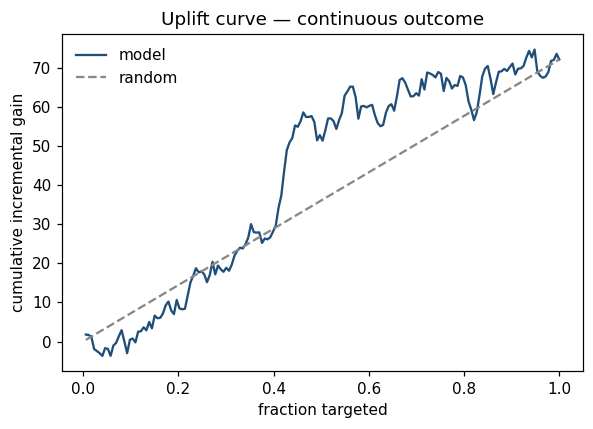

In [13]:
plot_uplift_curve(
    auuc_metrics["outcome"],
    auuc_metrics["is_treated"],
    auuc_metrics["uplift_model"],
    title="Uplift curve — continuous outcome",
)
print("Qini coefficient:", round(qini_coefficient(
    auuc_metrics["outcome"], auuc_metrics["is_treated"], auuc_metrics["uplift_model"]
), 4))
plt.show()


For a single transparent tree on a continuous outcome, `InteractionTree` splits to maximize the squared difference in treatment effects between child nodes. The leaf value is the difference in sample means.


In [14]:
rng_bin = np.random.default_rng(111)
df_bin = df[df["treatment_group_key"].isin(["control", "treatment1"])].reset_index(drop=True)
X_all = df_bin[x_names].to_numpy()
y_all = df_bin["outcome"].to_numpy()
w_all = (df_bin["treatment_group_key"].to_numpy() != "control").astype(int)
idx_bin = rng_bin.choice(len(df_bin), size=int(0.8 * len(df_bin)), replace=False)
test_bin = np.setdiff1d(np.arange(len(df_bin)), idx_bin)
X_train, y_train, w_train = X_all[idx_bin], y_all[idx_bin], w_all[idx_bin]
X_test_bin, y_test, w_test = X_all[test_bin], y_all[test_bin], w_all[test_bin]
print(X_train.shape, X_test_bin.shape)


(774, 10) (194, 10)


### Interaction tree: string and plot

In [15]:
it_fit = InteractionTree(max_depth=3, min_samples_leaf=40, random_state=111)
it_fit.fit(X_train, w_train, y_train, feature_names=x_names)
print(format_uplift_tree(it_fit))


[x2 <= -0.112]  gain=88.7532  tau=0.124  n=774
  [x7 <= -0.820]  gain=153.1396  tau=-0.308  n=387
    * leaf  tau=-1.562  n=78
    [x2 <= -0.377]  gain=108.2184  tau=0.006  n=309
      * leaf  tau=0.331  n=247
      * leaf  tau=-1.146  n=62
  [x5 <= -0.849]  gain=70.2068  tau=0.370  n=387
    * leaf  tau=1.203  n=78
    [x9 <= -0.842]  gain=48.0854  tau=0.142  n=309
      * leaf  tau=0.925  n=62
      * leaf  tau=-0.060  n=247


Leaf labels show **$\tau \approx \mathbb{E}[Y \mid T{=}1] - \mathbb{E}[Y \mid T{=}0]$** in that region.

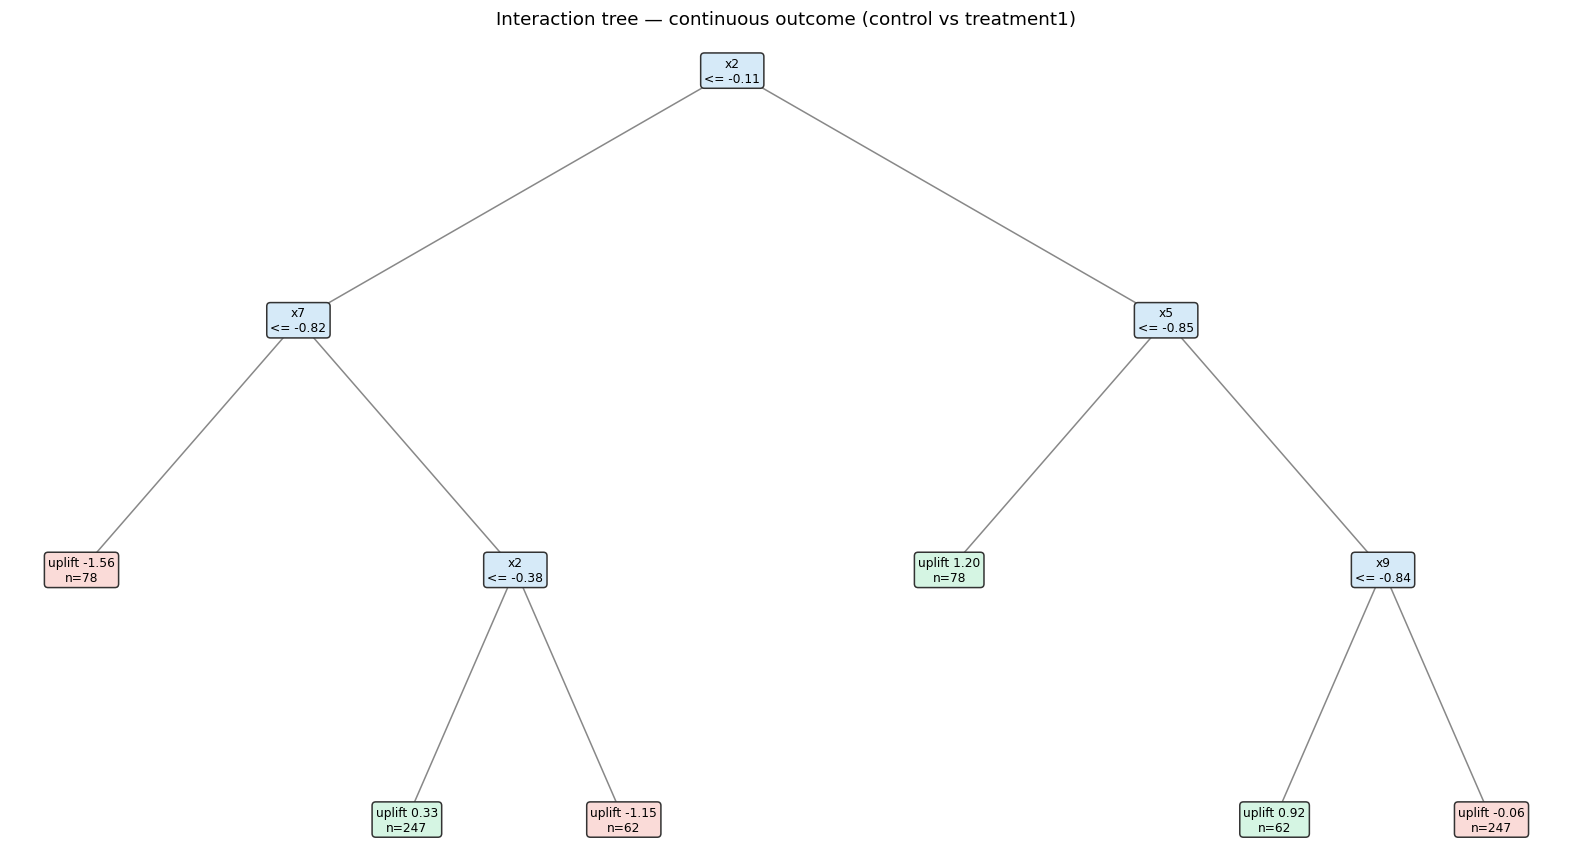

In [16]:
plot_uplift_tree(it_fit, title="Interaction tree — continuous outcome (control vs treatment1)")
plt.show()


### Honest causal tree

`CausalTree` is the honest single-tree estimator: one sample chooses the splits and a held-out sample estimates the leaf treatment effects. It is the interpretable counterpart of a causal inference tree.


    cate    n                                    conditions
0 -0.435   36                  x2 <= 0.086 AND x7 <= -0.914
1  1.236   71  x2 <= 0.086 AND x7 > -0.914 AND x9 <= -0.483
2 -0.751  122   x2 <= 0.086 AND x7 > -0.914 AND x9 > -0.483
3  0.274   37    x2 > 0.086 AND x6 <= 0.507 AND x8 <= 0.064
4  0.875   65     x2 > 0.086 AND x6 <= 0.507 AND x8 > 0.064
5  0.078   56                     x2 > 0.086 AND x6 > 0.507


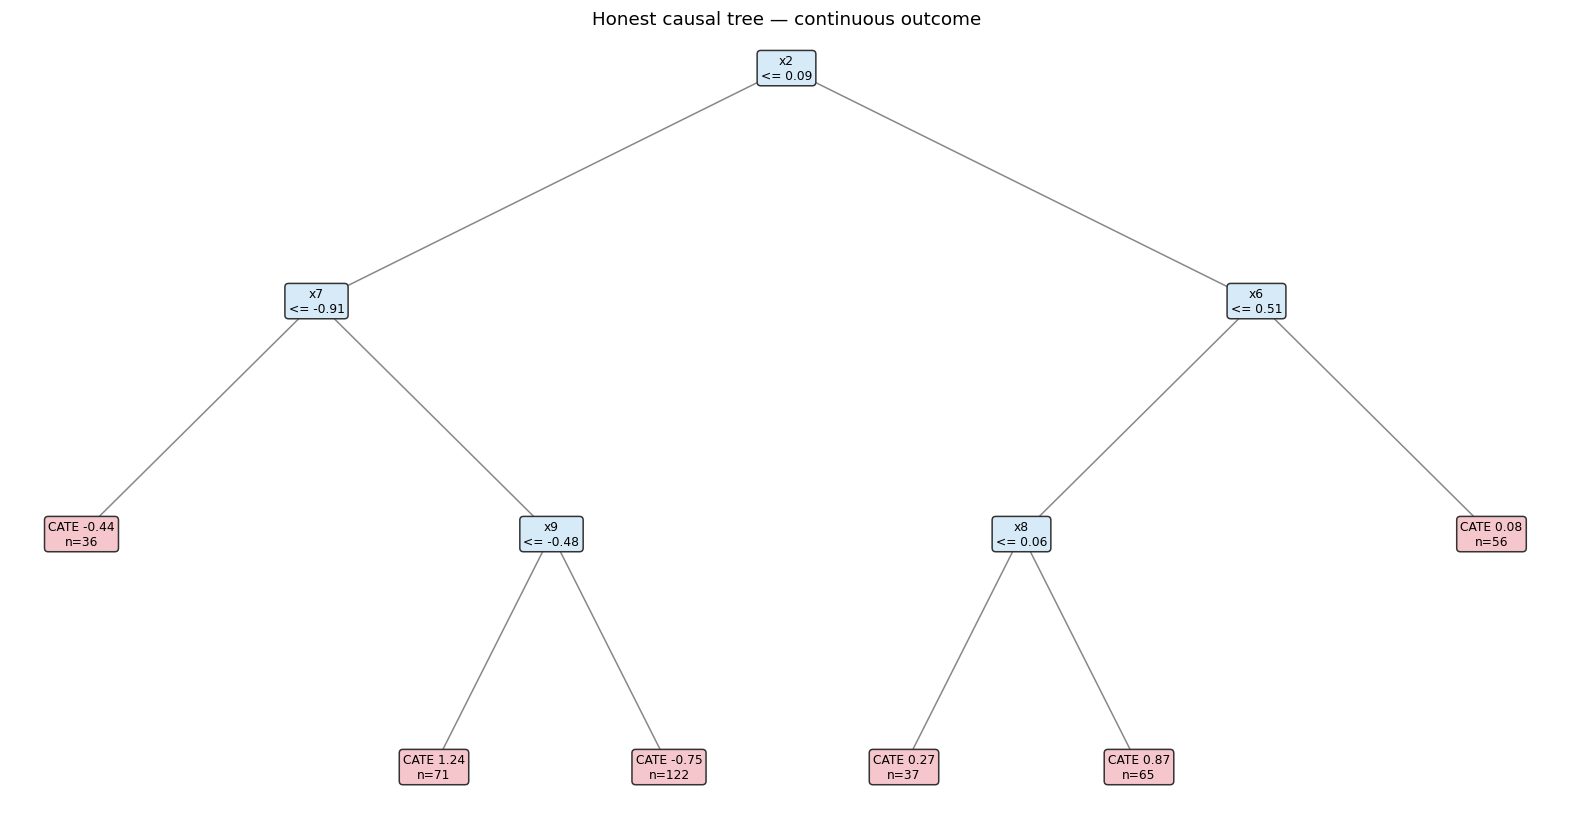

In [17]:
cit_fit = CausalTree(max_depth=3, min_samples_leaf=40, honest=True, random_state=111)
cit_fit.fit(X_train, w_train, y_train, feature_names=x_names)
print(pd.DataFrame(cit_fit.rules()).round(3))
plot_causal_tree(cit_fit, title="Honest causal tree — continuous outcome")
plt.show()


### Train versus test mean CATE

A `TLearner` with random-forest base learners estimates the conditional means on the same binary sample. Compare the mean predicted CATE on train and test rows.


In [18]:
uplift_bin = TLearner(learner="rf", n_estimators=40, random_state=111)
uplift_bin.fit(X_train, w_train, y_train, feature_names=x_names)
pred_tr = uplift_bin.predict(X_train)
pred_te = uplift_bin.predict(X_test_bin)
print(
    "Mean predicted CATE — train:", round(float(pred_tr.mean()), 4),
    " test:", round(float(pred_te.mean()), 4),
)


Mean predicted CATE — train: 0.1072  test: 0.1528


A T-learner stores two outcome models, not a list of uplift trees, so a forest diagram does not apply. Variable importance below is the average impurity importance of the two random forests. `InteractionTree` is the model to draw when the split rules themselves matter.


In [19]:
imp = 0.5 * (
    np.asarray(uplift_bin.mu0_.feature_importances_)
    + np.asarray(uplift_bin.mu1_.feature_importances_)
)
order = np.argsort(imp)[::-1]
print(pd.Series(imp[order], index=np.asarray(x_names)[order]).round(4).head(8))


x3    0.2533
x0    0.1900
x1    0.1839
x4    0.1795
x2    0.1724
x9    0.0052
x6    0.0047
x7    0.0044
dtype: float64


### One control + multiple treatments: interaction tree on "any treatment"

As in the classification notebook, we can code **any non-control** as treated and fit one interaction tree to summarize heterogeneity in the **average** lift of treatment packages vs control on the continuous outcome.

In [20]:
df_multi, X_names_multi = make_uplift_regression(
    treatment_name=("control", "treatment1", "treatment2", "treatment3"),
y_name="outcome",
n_samples=2000,
n_regression_features=10,
n_regression_informative=5,
n_uplift_increase_dict={"treatment1": 5, "treatment2": 5, "treatment3": 5},
n_uplift_decrease_dict={"treatment1": 3, "treatment2": 3, "treatment3": 3},
delta_uplift_increase_dict={"treatment1": 0.4, "treatment2": 0.6, "treatment3": 0.8},
delta_uplift_decrease_dict={"treatment1": -0.35, "treatment2": -0.35, "treatment3": -0.35},
random_seed=111,
    sigma=1.0,
)


In [21]:
rng_m = np.random.default_rng(111)
idx_m = rng_m.choice(len(df_multi), size=int(0.8 * len(df_multi)), replace=False)
w_multi = (df_multi["treatment_group_key"].to_numpy() != "control").astype(int)
X_multi = df_multi[X_names_multi].to_numpy()
y_multi = df_multi["outcome"].to_numpy()


In [22]:
it_multi = InteractionTree(max_depth=3, min_samples_leaf=40, random_state=111)
it_multi.fit(X_multi[idx_m], w_multi[idx_m], y_multi[idx_m], feature_names=X_names_multi)
print(format_uplift_tree(it_multi))


[x1 <= -0.035]  gain=239.6509  tau=0.287  n=1600
  [x3 <= -0.370]  gain=146.6864  tau=-0.118  n=800
    [x6 <= -0.375]  gain=90.5378  tau=-0.696  n=280
      * leaf  tau=0.034  n=98
      * leaf  tau=-1.159  n=182
    [x7 <= -0.829]  gain=132.8801  tau=0.202  n=520
      * leaf  tau=-0.821  n=104
      * leaf  tau=0.443  n=416
  [x1 <= 0.895]  gain=89.7990  tau=0.656  n=800
    [x8 <= 0.283]  gain=69.9957  tau=0.917  n=520
      * leaf  tau=0.668  n=338
      * leaf  tau=1.437  n=182
    [x4 <= -0.039]  gain=97.9436  tau=0.215  n=280
      * leaf  tau=-0.372  n=140
      * leaf  tau=0.810  n=140


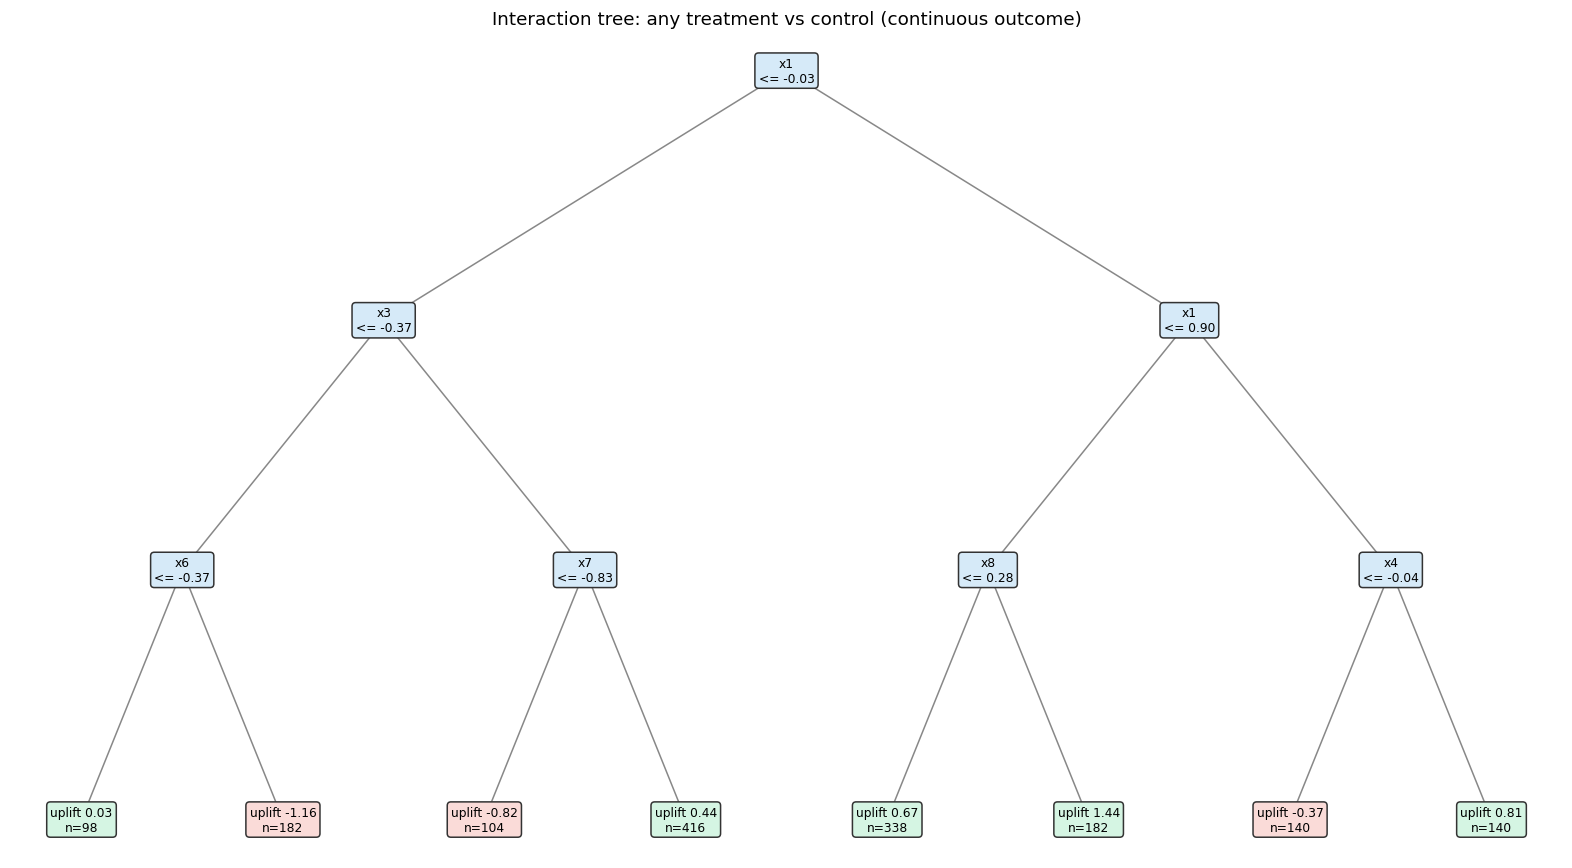

In [23]:
plot_uplift_tree(it_multi, title="Interaction tree: any treatment vs control (continuous outcome)")
plt.show()


### Distribution of predicted CATE (binary T-learner)

In [24]:
uf = TLearner(learner="rf", n_estimators=40, random_state=111)
uf.fit(X_all, w_all, y_all, feature_names=x_names)
pred_cate = uf.predict(X_all)


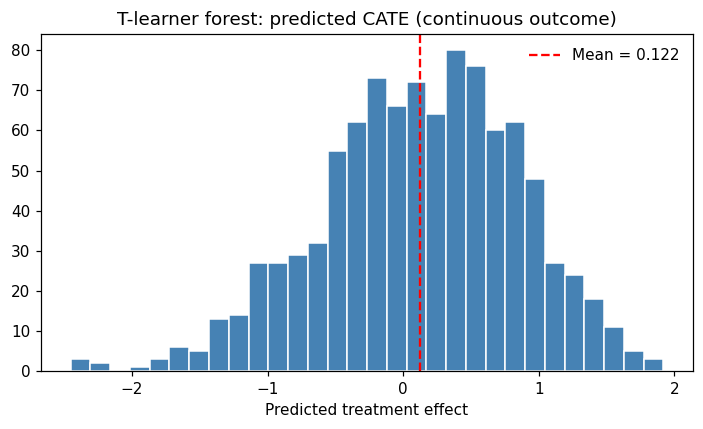

In [25]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(pred_cate, bins=30, color="steelblue", edgecolor="white")
ax.axvline(pred_cate.mean(), color="red", ls="--", label=f"Mean = {pred_cate.mean():.3f}")
ax.set_xlabel("Predicted treatment effect")
ax.set_title("T-learner forest: predicted CATE (continuous outcome)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()


### Permutation SHAP for predicted uplift

`explain` attributes $\hat{\tau}(X)$ from the binary T-learner. Positive SHAP pushes the predicted CATE up. The explanation is about treatment-effect heterogeneity, not the raw outcome.


In [26]:
sv = uplift_bin.explain(X_train, max_samples=30, n_permutations=6, random_state=2026)
print("SHAP array shape:", sv.values.shape)


SHAP array shape: (30, 10)


#### SHAP summary plot (beeswarm + importance)

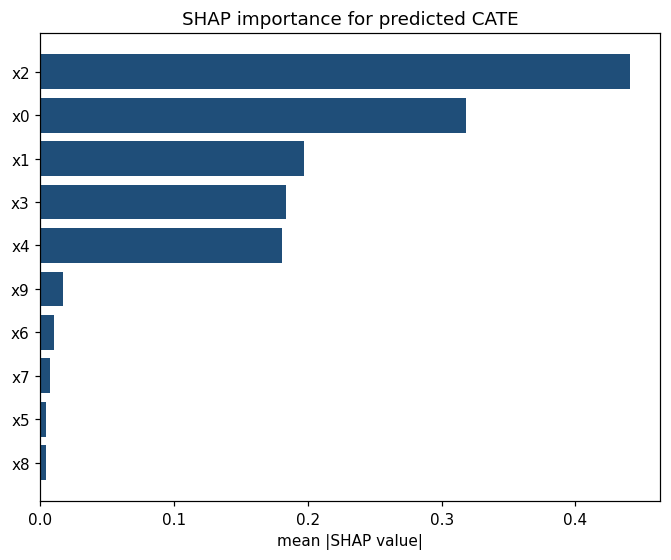

In [27]:
sv.plot_importance(title="SHAP importance for predicted CATE")
plt.show()


#### SHAP dependence plots (main effects)

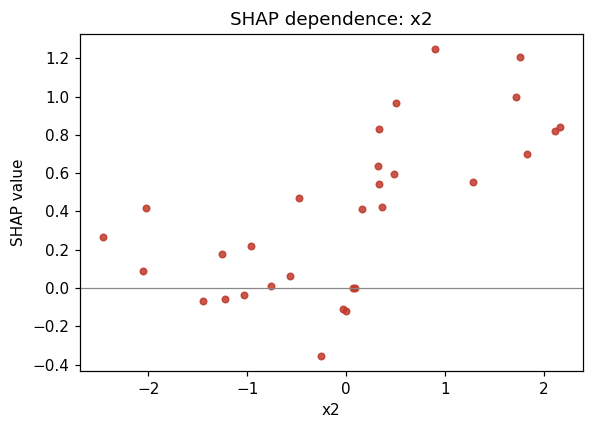

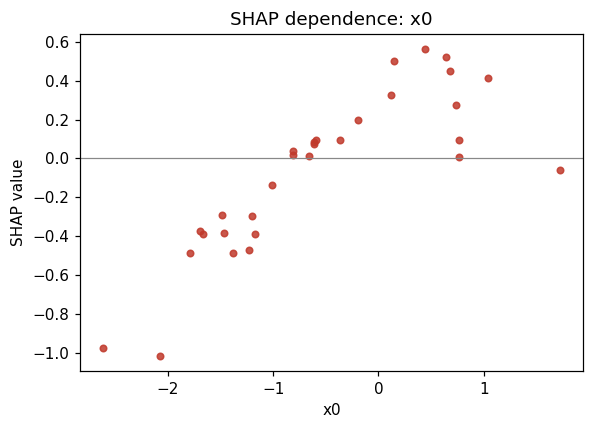

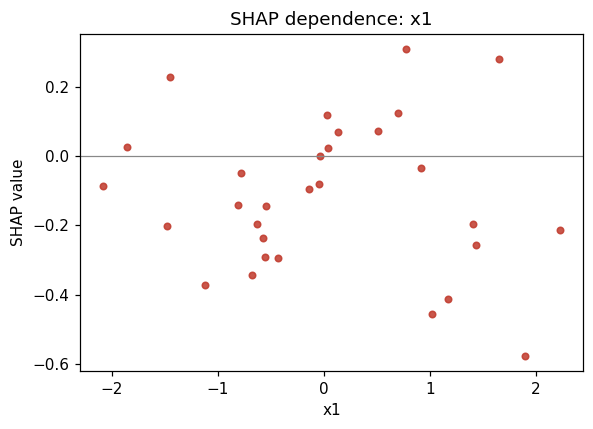

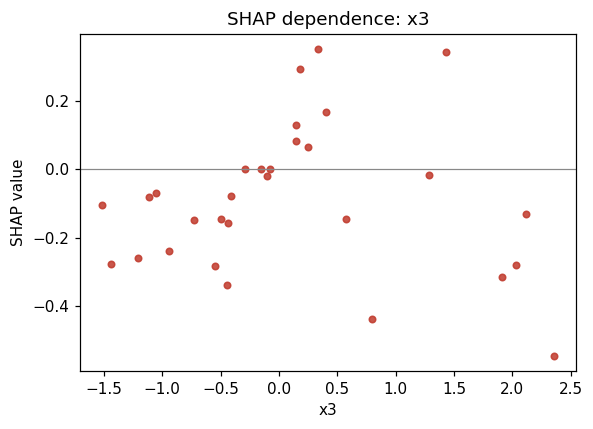

In [28]:
order = np.argsort(sv.importance())[::-1][:4]
for feature in np.asarray(x_names)[order]:
    sv.plot_dependence(feature)
    plt.show()


Single covariate with a color interaction:

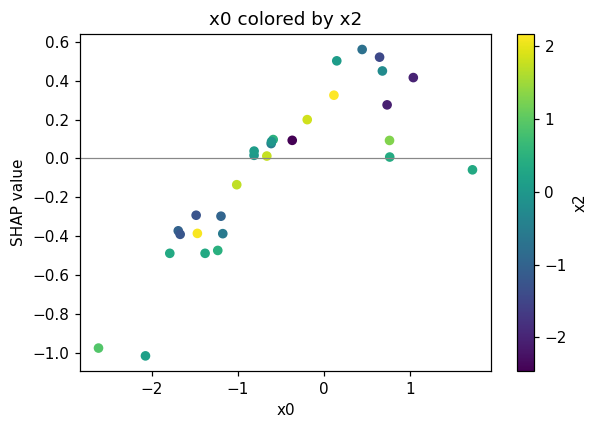

In [29]:
if len(order) >= 2:
    j, k = int(order[1]), int(order[0])
    fig, ax = plt.subplots(figsize=(5.6, 4))
    points = ax.scatter(sv.data[:, j], sv.values[:, j], c=sv.data[:, k], cmap="viridis", s=28)
    fig.colorbar(points, ax=ax, label=x_names[k])
    ax.axhline(0, color="#888888", lw=0.8)
    ax.set_xlabel(x_names[j])
    ax.set_ylabel("SHAP value")
    ax.set_title(f"{x_names[j]} colored by {x_names[k]}")
    fig.tight_layout()
    plt.show()


#### Waterfall / force plot for a single observation

Highest predicted CATE in the explain set: 1.5481


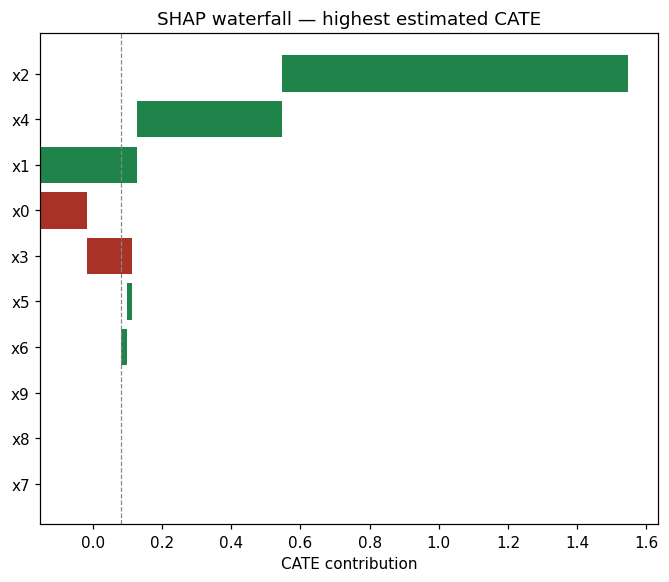

In [30]:
row_id = int(np.argmax(sv.predictions))
print("Highest predicted CATE in the explain set:", round(float(sv.predictions[row_id]), 4))
sv.plot_waterfall(row_id, title="SHAP waterfall — highest estimated CATE")
plt.show()


#### Optional: explain a few test rows

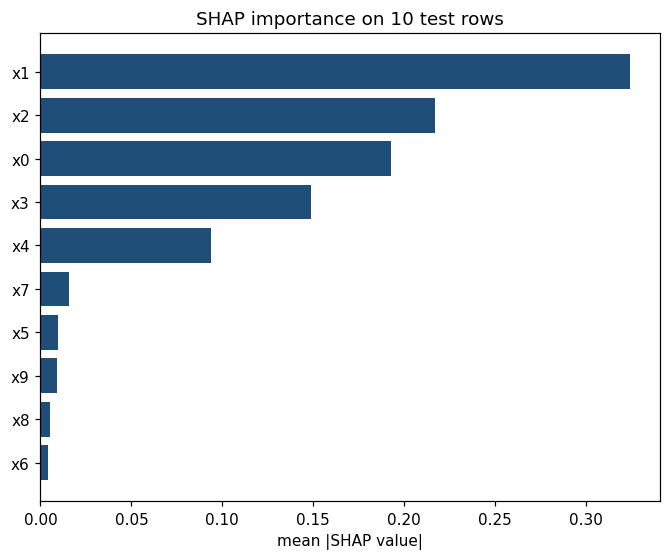

In [31]:
sv_test = uplift_bin.explain(X_test_bin[:10], max_samples=10, n_permutations=6, random_state=2026)
sv_test.plot_importance(title="SHAP importance on 10 test rows")
plt.show()


#### Interpretation notes

- **Positive SHAP** pushes the predicted **CATE** up; **negative SHAP** pushes it down.
- Explanations target **heterogeneity in** $\hat{\tau}(X)$, not the raw outcome margin $\mathbb{E}[Y \mid X]$.
- `explain` is model-agnostic: it calls `predict` on the T-learner and attributes the predicted CATE.

## Summary

With a continuous outcome, a `TLearner` (or `UpliftXGBoost`) estimates $\hat{\mu}_1(x) - \hat{\mu}_0(x)$ separately in each arm. `InteractionTree` and `CausalTree` publish the partition. The Qini curve and `explain` are the same evaluation tools as in the classification notebook, with the outcome column `outcome` instead of `conversion`.


## References

- [Uplift Trees Example with Synthetic Data (Python CausalML)](https://causalml.readthedocs.io/en/latest/examples/uplift_trees_with_synthetic_data.html)
- Gutierrez and Gérardy (2017), [Causal inference and uplift modelling: A review of the literature](http://proceedings.mlr.press/v67/gutierrez17a/gutierrez17a.pdf)